In [ ]:
!pip install torch gpytorch botorch

## Define Objective Function

In [3]:
import torch
import numpy as np
import gpytorch

In [11]:
# Convert CMY volumes to RGB
# goal: achieve specific RGB values to optimize color accuracy
# input: CMY volumes, output: RGB values

# define sample batch of target RGB values
target_rgb_batch = torch.tensor([
    [150.0, 100.0, 200.0],
    [100.0, 150.0, 50.0],
    [200.0, 200.0, 100.0]
], dtype=torch.float64) 

# minimize distance between batches of generated and target RGBs
def objective_from_cmy_batch(batch_size=10):
    max_volume = 270  # volume constraint in microliters
    num_targets = target_rgb_batch.size(0)  # number of target RGB values

    # generate batch samples of CMY volumes
    # use random.dirichlet to divide into parts and ensure parts collectively
    proportions = np.random.dirichlet([1, 1, 1], size=batch_size)  
    cmy_volumes = proportions * max_volume  # scale by max volume constraint
    V_c, V_m, V_y = cmy_volumes[:, 0], cmy_volumes[:, 1], cmy_volumes[:, 2]

    # convert CMY volumes to RGB values
    R = 255 * (1 - V_c / max_volume)
    G = 255 * (1 - V_m / max_volume)
    B = 255 * (1 - V_y / max_volume)
    generated_rgb = torch.tensor(np.column_stack([R, G, B]), dtype=torch.float64)

    # calculate error for each target RGB in the batch
    errors = []
    for target_rgb in target_rgb_batch:
        error = torch.sqrt(torch.sum((generated_rgb - target_rgb) ** 2, dim=1))
        errors.append(error)

    # stack errors for all targets to create a batch of errors, then take mean across all
    errors = torch.stack(errors, dim=1)  # shape: (batch_size, num_targets)
    mean_error = errors.mean()  # overall mean error across all generated and target pairs

    return mean_error, generated_rgb, cmy_volumes, errors


## Set up Gaussian Process Model

### Generate Training Data

In [12]:
# Generate initial data
num_initial_points = 20
CMY_samples = torch.tensor([objective_from_cmy_batch()[1] 
                            for _ in range(num_initial_points)], dtype=torch.float64)
RGB_targets = torch.stack([objective_from_cmy_batch()[0] 
                           for _ in range(num_initial_points)]).to(torch.float64)

ValueError: only one element tensors can be converted to Python scalars

### Train GP Model on CMY-to-RGB Mapping

In [5]:
from botorch.acquisition.analytic import LogExpectedImprovement
from botorch.acquisition.objective import ScalarizedPosteriorTransform

def find_cmy_for_rgb(target_rgb):
    # Calculate the best observed value using Euclidean distance from the target
    best_f = (RGB_targets - target_rgb).norm(dim=-1).min()  # Euclidean distance to target
    
    # Define a posterior transform that weights each RGB channel equally
    posterior_transform = ScalarizedPosteriorTransform(weights=torch.tensor([1.0, 1.0, 1.0], dtype=torch.float64))
    
    # Create the LogExpectedImprovement acquisition function
    acq_func = LogExpectedImprovement(model, best_f=best_f, posterior_transform=posterior_transform, maximize=False)
    
    # Optimize the acquisition function to find CMY volumes
    cmy_optimal, _ = optimize_acqf(
        acq_func,
        bounds=torch.tensor([[0.0, 0.0, 0.0], [270.0, 270.0, 270.0]], dtype=torch.float64),
        q=1,
        num_restarts=10,
        raw_samples=100
    )
    return cmy_optimal

In [6]:
# Define the target RGB as a tensor
target_rgb = torch.tensor([209.45, 179.93, 120.62], dtype=torch.float64)

# Find the optimal CMY values that produce RGB closest to the target
optimal_cmy = find_cmy_for_rgb(target_rgb)

# Print the results
print("Optimal CMY Volumes (microliters):", optimal_cmy.detach().numpy())

NameError: name 'model' is not defined

### Function to optimize for CMY values

In [ ]:
def find_cmy_for_rgb(target_rgb):
    # Define the acquisition function (Posterior Mean for direct optimization)
    acq_func = PosteriorMean(model)

    # Optimize CMY values to match target RGB values
    cmy_optimal, _ = optimize_acqf(
        acq_func,
        bounds=bounds,
        q=1,
        num_restarts=10,
        raw_samples=100,
        target=target_rgb,  # Set the target RGB value for optimization
    )
    return cmy_optimal

In [ ]:
# Example: Finding CMY volumes for a target RGB value
target_rgb = torch.tensor([209.45, 179.93, 120.62])
optimal_cmy = find_cmy_for_rgb(target_rgb)

print("Optimal CMY Volumes:", optimal_cmy)

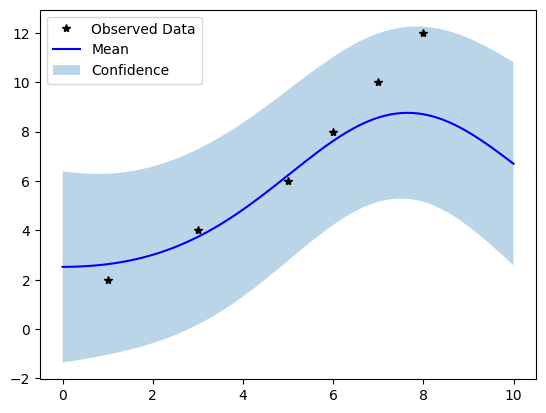

In [7]:
from matplotlib import pyplot as plt

# Training data
X_train = torch.tensor([1, 3, 5, 6, 7, 8], dtype=torch.float).view(-1, 1)
y_train = torch.tensor([2, 4, 6, 8, 10, 12], dtype=torch.float)

# Define a custom GP model
class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super(ExactGPModel, self).__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

# Define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ExactGPModel(X_train, y_train, likelihood)

# Training the model
model.train()
likelihood.train()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)  # Optimizer
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

# Training loop
training_iter = 50
for i in range(training_iter):
    optimizer.zero_grad()
    output = model(X_train)
    loss = -mll(output, y_train)
    loss.backward()
    optimizer.step()

# Make predictions
model.eval()
likelihood.eval()
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    X_test = torch.linspace(0, 10, 100)
    y_pred = likelihood(model(X_test))

# Plot results
plt.figure()
plt.plot(X_train.numpy(), y_train.numpy(), 'k*')
plt.plot(X_test.numpy(), y_pred.mean.numpy(), 'b')
plt.fill_between(X_test.numpy(), 
                 y_pred.mean.numpy() - 2 * y_pred.variance.sqrt().numpy(),
                 y_pred.mean.numpy() + 2 * y_pred.variance.sqrt().numpy(), alpha=0.3)
plt.legend(['Observed Data', 'Mean', 'Confidence'])
plt.show()

## Optimize using BO

In [8]:
# for multi-output
from botorch.acquisition.analytic import ExpectedImprovement
from botorch.models.transforms import Standardize

# Apply Standardize transform to handle multiple outputs if necessary
gp = SingleTaskGP(initial_points.to(torch.float64), initial_rgb_values.to(torch.float64), outcome_transform=Standardize(m=3))
gp.train()

# Define acquisition function with ExpectedImprovement
best_rgb_value = initial_rgb_values.max(dim=0).values
acq_func = ExpectedImprovement(gp, best_f=best_rgb_value)


NameError: name 'SingleTaskGP' is not defined

In [9]:
# Ensure both initial_points and initial_rgb_values are of the same dtype (e.g., torch.float32)
initial_points = initial_points.to(dtype=torch.float32)
initial_rgb_values = initial_rgb_values.to(dtype=torch.float32)

# Fit GP model
gp = SingleTaskGP(initial_points, initial_rgb_values)
gp.train()  # Train the GP model

# Define the acquisition function
best_rgb_value = initial_rgb_values.max(dim=0).values
acq_func = ExpectedImprovement(gp, best_f=best_rgb_value)


NameError: name 'initial_points' is not defined

In [ ]:
"""
Considerations:
- hyperparameter tuning
- initial samples can impact convergence speed (try eg.Latin Hypercube Sampling)
- define stopping criteria (ie. max number of iterations, convergence of objective function,
    or reaching a certain performance threshold)
- color values contrained between 0 and 255 for RGB
"""

In [ ]:
how# Initialize lists to track best RGB values and iterations
best_rgb_values = []
iterations = []

# Bayesian Optimization loop
n_iterations = 20  # Number of iterations
for i in range(n_iterations):
    # Optimize the acquisition function
    new_point, _ = optimize_acqf(
        acq_func,
        bounds=bounds,
        q=1,  # number of candidates to sample
        num_restarts=5,
        raw_samples=20,
    )

    # Evaluate the objective function at the new point
    new_rgb_value = rgb_from_cmy(new_point[0][0], new_point[0][1], new_point[0][2])
    
    # Update data
    initial_points = torch.cat([initial_points, new_point])
    initial_rgb_values = torch.cat([initial_rgb_values, new_rgb_value.unsqueeze(0)])

    # Store the best RGB value found
    best_rgb = initial_rgb_values.max(dim=0).values
    best_rgb_values.append(best_rgb.cpu().numpy())
    iterations.append(i + 1)

    # Refit the GP model
    gp = SingleTaskGP(initial_points, initial_rgb_values)
    gp.train()  # Train the GP model

# Convert best RGB values to a numpy array for plotting
best_rgb_values = np.array(best_rgb_values)

## Visualizing convergence of BO

In [ ]:
!pip install matplotlib

In [ ]:
"""
Exploitation:
Visualize how RGB values converge over iterations of the BO process. Basically, it tracks
the best RGB output obtained after each iteration of optimization.
"""

def plot_convergence(iterations, best_rgb_values):
    plt.figure(figsize=(12, 6))
    
    # Plot each RGB channel
    plt.subplot(3, 1, 1)
    plt.plot(iterations, best_rgb_values[:, 0], label='Red', color='red')
    plt.ylabel('Red Channel Value')
    plt.title('Convergence of RGB Values')
    plt.grid()
    plt.legend()

    plt.subplot(3, 1, 2)
    plt.plot(iterations, best_rgb_values[:, 1], label='Green', color='green')
    plt.ylabel('Green Channel Value')
    plt.grid()
    plt.legend()

    plt.subplot(3, 1, 3)
    plt.plot(iterations, best_rgb_values[:, 2], label='Blue', color='blue')
    plt.ylabel('Blue Channel Value')
    plt.xlabel('Iterations')
    plt.grid()
    plt.legend()

    plt.tight_layout()
    plt.show()

# Call the plot function after the optimization loop
plot_convergence(iterations, best_rgb_values)

In [ ]:
"""
Exploration:
Visualizes the predicted RGB values based on CMY values as predicted by the Gaussian
Process model. Basically, it helps in understanding the model's output across the 
entire input space.
"""

# Define a grid of CMY values for visualization
num_points = 100
cmy_grid = torch.linspace(0.0, 1.0, num_points)
cmy_mesh = torch.cartesian_prod(cmy_grid, cmy_grid, cmy_grid)

# Predict RGB values using the GP model
with torch.no_grad():
    gp.eval()
    pred_mean = gp.posterior(cmy_mesh).mean.detach()
    pred_var = gp.posterior(cmy_mesh).variance.detach()

# Visualize predictions
def plot_gp_predictions(cmy_mesh, pred_mean, pred_var):
    # Convert CMY to RGB for a scatter plot
    rgb_values = pred_mean.numpy()
    
    plt.figure(figsize=(10, 10))
    scatter = plt.scatter(rgb_values[:, 0], rgb_values[:, 1], c=rgb_values, s=10)
    plt.colorbar(scatter, label='RGB Value')
    plt.xlabel('Red Channel Value')
    plt.ylabel('Green Channel Value')
    plt.title('GP Predictions in RGB Space')
    plt.grid()
    plt.show()

plot_gp_predictions(cmy_mesh, pred_mean, pred_var)